# JS11 – Klasifikasi 2: Praktikum 1
## Klasifikasi SVM dengan Data Dummy Linier

**Tujuan praktikum**

1. Memahami konsep **hyperplane**, **margin**, dan **support vector** pada SVM.
2. Melatih SVM dengan kernel linear pada data dummy yang terpisah secara linear.
3. Memvisualisasikan garis pemisah, margin, dan support vector.
4. Menunjukkan bahwa titik yang jauh dari margin tidak memengaruhi posisi hyperplane.
5. Membedakan pengaruh jumlah data terhadap support vector dan model.

**Tentang data:** Data dibuat dengan `make_blobs` sebanyak 50 sampel, 2 fitur, 2 pusat kelas, dan `cluster_std=0.60`. Data ini sengaja dibuat hampir terpisah sempurna agar konsep hard margin dapat diilustrasikan dengan jelas.

> SVM mencari hyperplane yang memaksimalkan margin, yaitu jarak antara hyperplane dengan titik terdekat dari setiap kelas. Titik terdekat tersebut adalah **support vector**. Pada kernel linear, hyperplane berbentuk garis lurus.

### 0. Import library

In [1]:
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import make_blobs
from sklearn.svm import SVC

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 6)

print("Python  :", platform.python_version())
print("NumPy   :", np.__version__)
print("pandas  :", pd.__version__)
print("seaborn :", sns.__version__)

Python  : 3.12.3
NumPy   : 2.5.4
pandas  : 3.0.6
seaborn : 0.13.2


### 1. Membuat data dummy linier

Bentuk X: (50, 2)
Bentuk y: (50,)
Distribusi kelas: [25 25]


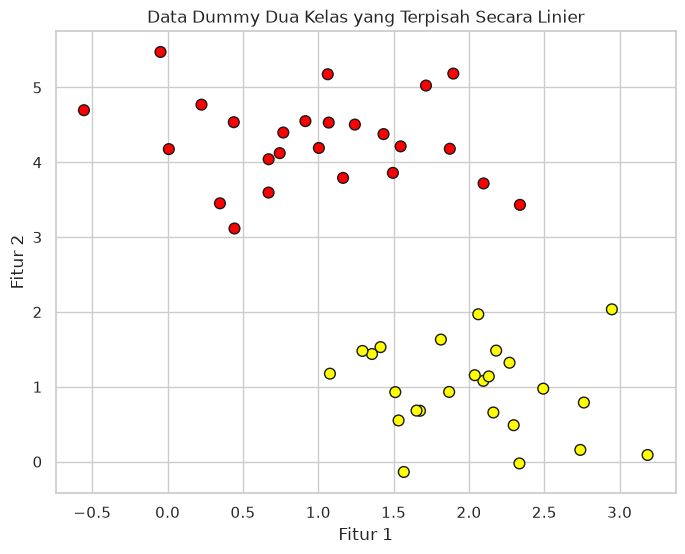

In [2]:
X, y = make_blobs(
    n_samples=50,
    centers=2,
    random_state=0,
    cluster_std=0.60,
)

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)
print("Distribusi kelas:", np.bincount(y))

plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap="autumn", edgecolor="k")
plt.title("Data Dummy Dua Kelas yang Terpisah Secara Linier")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

### 2. Banyak garis yang mungkin memisahkan data

Secara visual, ada banyak garis lurus yang bisa memisahkan kedua kelas. Namun, tidak semuanya sama baiknya. SVM memilih garis yang memberi **margin terbesar**, sehingga model lebih tahan terhadap noise dan data baru.

Ilustrasi berikut menunjukkan tiga garis pemisah dengan margin yang berbeda.

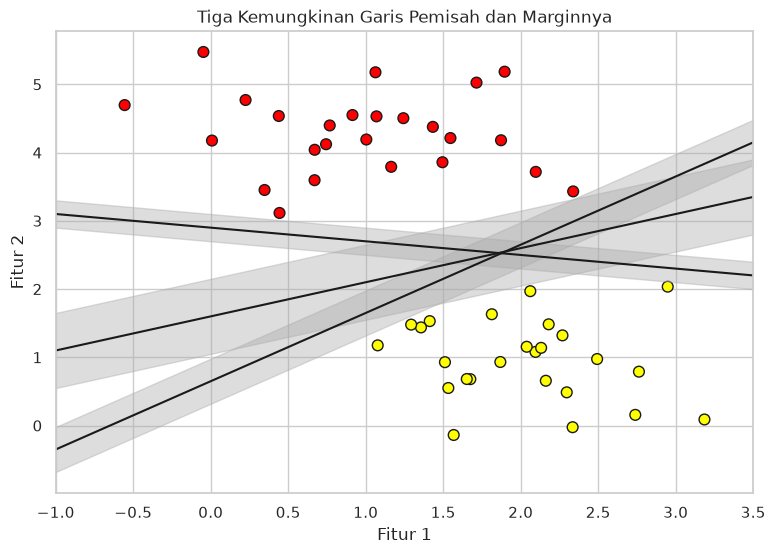

In [3]:
xfit = np.linspace(-1, 3.5)

plt.figure(figsize=(9, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap="autumn", edgecolor="k")

for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
    yfit = m * xfit + b
    plt.plot(xfit, yfit, "-k")
    plt.fill_between(
        xfit,
        yfit - d,
        yfit + d,
        edgecolor="none",
        color="#AAAAAA",
        alpha=0.4,
    )

plt.xlim(-1, 3.5)
plt.title("Tiga Kemungkinan Garis Pemisah dan Marginnya")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.show()

### 3. Melatih SVM dengan kernel linear

Nilai `C=1E10` membuat penalti kesalahan sangat besar. Pada data yang terpisah sempurna, model berperilaku seperti **hard margin**: semua titik harus berada di sisi yang benar dan margin dimaksimalkan.

In [4]:
model = SVC(kernel="linear", C=1e10)
model.fit(X, y)

print("Akurasi pada data latih:", model.score(X, y))
print("Jumlah support vector   :", len(model.support_vectors_))
print("\nSupport vectors:")
print(model.support_vectors_)
print("\nIndeks support vector pada data:")
print(model.support_)
print("\nNilai decision_function pada support vector:")
print(model.decision_function(model.support_vectors_))

Akurasi pada data latih: 1.0
Jumlah support vector   : 3

Support vectors:
[[0.44359863 3.11530945]
 [2.33812285 3.43116792]
 [2.06156753 1.96918596]]

Indeks support vector pada data:
[18 25  7]

Nilai decision_function pada support vector:
[-0.99969781 -1.00015041  0.999849  ]


Support vector adalah titik yang menyentuh batas margin. Nilai `decision_function` untuk support vector berada di sekitar `-1` atau `+1`. Titik-titik lain memiliki nilai di luar rentang tersebut dan **tidak** ikut menentukan posisi hyperplane.

### 4. Fungsi visualisasi decision boundary

In [5]:
def plot_svc_decision_function(model, ax=None, plot_support=True):
    '''Plot decision boundary, margin, dan support vector untuk SVM 2D.'''
    if ax is None:
        ax = plt.gca()

    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Grid untuk mengevaluasi decision function
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # Garis batas (0) dan margin (-1, +1)
    ax.contour(
        X_grid,
        Y,
        P,
        colors="k",
        levels=[-1, 0, 1],
        alpha=0.6,
        linestyles=["--", "-", "--"],
    )

    if plot_support:
        ax.scatter(
            model.support_vectors_[:, 0],
            model.support_vectors_[:, 1],
            s=300,
            linewidth=1,
            facecolors="none",
            edgecolors="k",
            label="Support vector",
        )

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)

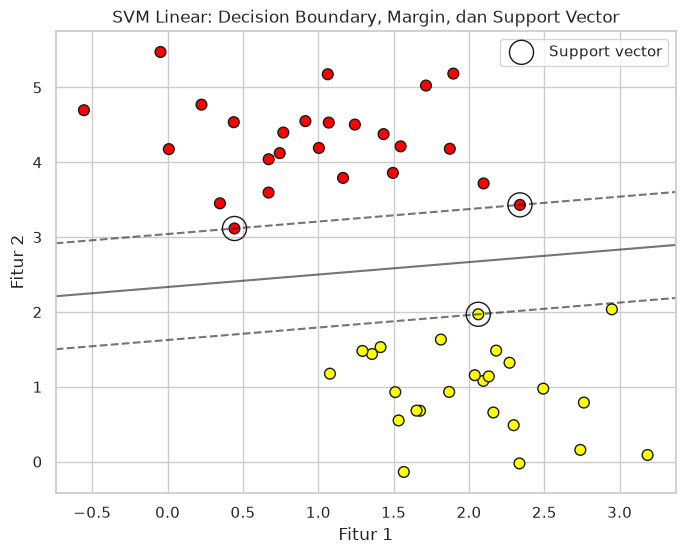

In [6]:
plt.figure(figsize=(8, 6))
plt.scatter(X[:, 0], X[:, 1], c=y, s=60, cmap="autumn", edgecolor="k")
plot_svc_decision_function(model)
plt.title("SVM Linear: Decision Boundary, Margin, dan Support Vector")
plt.xlabel("Fitur 1")
plt.ylabel("Fitur 2")
plt.legend()
plt.show()

Garis hitam solid adalah **hyperplane** (decision boundary). Dua garis putus-putus adalah batas margin. Tiga titik yang dilingkari adalah support vector. Hanya titik-titik inilah yang menentukan posisi garis pemisah.

### 5. Pengaruh jumlah data terhadap model

Kita bandingkan model yang dilatih dengan 60 dan 120 titik dari dataset yang sama. Selama support vector tidak berubah, hyperplane juga tidak berubah. Penambahan data yang jauh dari margin tidak mengubah model.

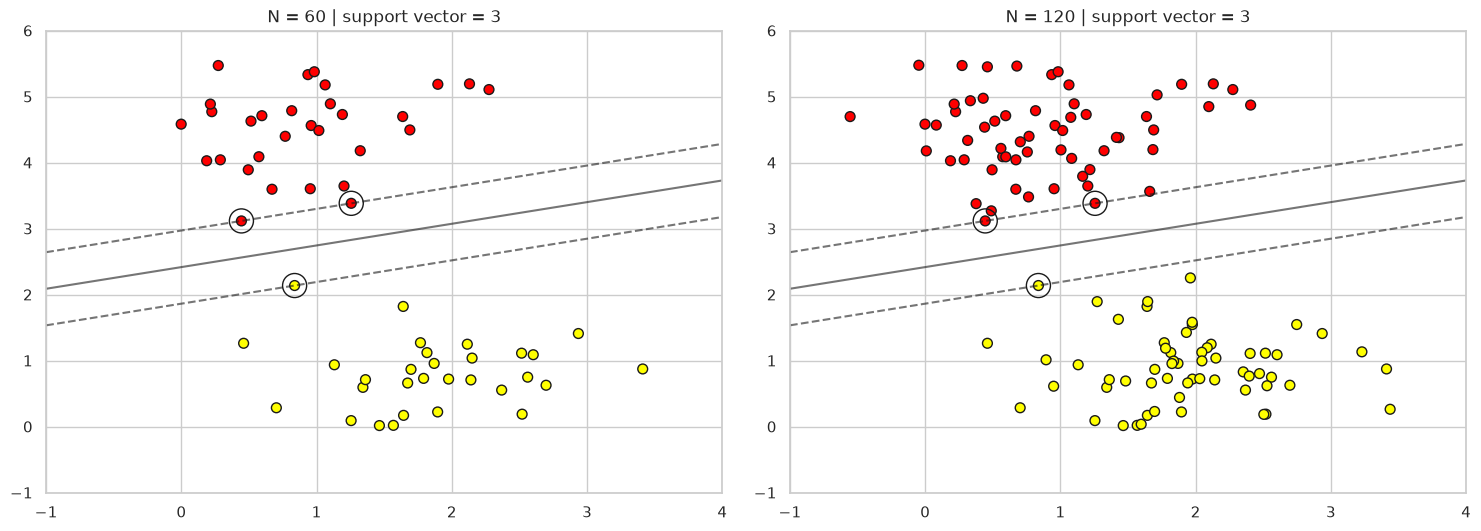

In [7]:
def plot_svm(N=10, ax=None):
    X_plot, y_plot = make_blobs(
        n_samples=200,
        centers=2,
        random_state=0,
        cluster_std=0.60,
    )
    X_plot = X_plot[:N]
    y_plot = y_plot[:N]

    model_plot = SVC(kernel="linear", C=1e10)
    model_plot.fit(X_plot, y_plot)

    ax = ax or plt.gca()
    ax.scatter(X_plot[:, 0], X_plot[:, 1], c=y_plot, s=50, cmap="autumn", edgecolor="k")
    ax.set_xlim(-1, 4)
    ax.set_ylim(-1, 6)
    plot_svc_decision_function(model_plot, ax)

    return model_plot


fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

for ax, N in zip(axes, [60, 120]):
    model_n = plot_svm(N, ax)
    ax.set_title(f"N = {N} | support vector = {len(model_n.support_vectors_)}")

plt.show()

### 6. Interpretasi dan kesimpulan

**Konsep utama**

- SVM mencari **hyperplane dengan margin terbesar**, bukan sekadar garis yang memisahkan kelas.
- **Support vector** adalah titik yang paling dekat dengan hyperplane dan menentukan posisi serta orientasi hyperplane.
- Titik yang jauh dari margin tidak memengaruhi model. Karena itu, menambah data yang mudah diklasifikasikan tidak selalu mengubah decision boundary.
- `C` mengontrol trade-off antara margin lebar dan pelanggaran margin. Pada percobaan ini `C=1E10` menghasilkan hard margin karena data dapat dipisahkan sempurna.

**Hasil**

- Akurasi data latih: **1,0**.
- Jumlah support vector: **3**.
- Support vector berada tepat pada batas margin dengan nilai decision function sekitar `-1` dan `+1`.
- Model dengan 60 dan 120 data menghasilkan boundary yang sama karena support vector-nya tetap.

**Keterbatasan**

- Data dummy ini terlalu mudah; hard margin tidak realistis untuk data nyata yang mengandung noise atau outlier.
- SVM dengan `C` sangat besar dapat overfitting pada data yang tidak terpisah sempurna.
- Visualisasi hanya berlaku untuk dua fitur; pada dimensi tinggi hyperplane tidak dapat digambar secara langsung.

**Kesimpulan**

1. SVM linear berhasil memisahkan data dummy dengan margin maksimum.
2. Hanya tiga support vector yang menentukan model.
3. Penambahan data yang jauh dari margin tidak mengubah decision boundary.
4. Pemahaman support vector penting untuk menjelaskan mengapa SVM relatif tahan terhadap noise.

### Referensi

- Modul Praktikum Pembelajaran Mesin JS11 – Klasifikasi 2, Politeknik Negeri Malang. https://polinema.gitbook.io/jti-modul-praktikum-pembelajaran-mesin-2025-2026/js11-klasifikasi-2
- `scikit-learn` – Support Vector Machines. https://scikit-learn.org/stable/modules/svm.html
- Müller, A. C., & Guido, S. (2016). *Introduction to Machine Learning with Python*. O'Reilly.
- StatQuest – Support Vector Machines. https://www.youtube.com/watch?v=efR1C6CvhmE